<a href="https://colab.research.google.com/github/gitmystuff/INFO5810/blob/main/Module_13-Rung_3/Explanations_Counterfactuals_Recourse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explaining Decisions: From Attribution to Counterfactuals and Recourse

Your Name

## Getting Started

* Colab - get notebook from gitmystuff INFO5810 repository
* Save a Copy in Drive
* Remove Copy of
* Edit your name in the cell above and the filename
* Clean up Colab Notebooks folder
* Submit shared link

**What you will be able to do after this notebook**
- Explain what SHAP and LIME can tell you about a decision, and why they stop at the first rung of the ladder.
- Describe a **structural causal model (SCM)**: a graph plus an equation for each variable plus a bit of noise that belongs to each individual case.
- Answer a **rung 2** question about a group ("what if people like her did X?") and a **rung 3** question about one person ("what would it take for *her*?").
- Build a **counterfactual explanation** and say why the nearest change is often not a useful one.
- Build **actionable recourse**: only actions a person can actually take, with costs, and with the downstream effects the graph predicts.
- Name the limits: a wrong graph gives wrong advice, and advice that everyone follows can weaken the very signal a model relies on.

**Where this fits.** Earlier we climbed the ladder from seeing to doing, and we left a door open to the third rung with questions about one specific claim. Today we walk through that door, and we do it while explaining one decision made by a model about one person.

## Part 0: Where we have been (quick recap)


| Idea we already know | One-line reminder | Where it comes back today |
|---|---|---|
| **Bayesian network and CPTs** | Nodes, arrows, and a probability table for each node, read as "given the parents, how likely is this state?" | Each CPT turns out to be a *recipe plus noise*, which is the heart of an SCM |
| **Bayes' theorem** | Update what we believe after we see evidence | The first move of a counterfactual is exactly this: update what we believe about *this* case |
| **Correlation is not causation** | Two things can move together because a third thing drives both (hot weather, shark bites, ice cream) | Receipts and witness statements move together because fraud drives both |
| **Forks, confounders, d-separation** | A common cause creates association; conditioning on the right thing blocks it | Why a clue is not a lever |
| **The ladder** | Seeing needs data. Doing needs data plus a graph. Imagining needs data, a graph, and equations. | The whole notebook is organized by it |
| **do() and graph surgery** | To force X, cut the arrows into X and set its value | How we test "what if she submitted more documents?" |
| **Backdoor adjustment, mediators** | Adjust for confounders, never for things on the causal path | Estimating what a document really does |
| **The individual drawer** | Every case has a payout (or outcome) in each possible world, and we only see one | Rung 3 asks for the drawer's contents for *one* case |
| **DoWhy** | Model, identify, estimate, refute | A quick cross-check of the effect we build by hand |



**"A common cause creates association; conditioning on the right thing blocks it"**

Fraud makes the receipts mismatch, and fraud also makes the witness statements inconsistent. Nothing connects the receipts to the witnesses directly. Still, when you look across all claims, high receipt mismatch tends to come with high witness inconsistency. They move together because the same hidden thing, fraud, is pushing both. That is the shark bites and ice cream pattern: hot weather drives both, and neither causes the other.

"Conditioning" means looking only at claims where the common cause (fraud) is held fixed. Look only at legitimate claims, for example. Among legitimate claims, where there is no fraud, bad receipts and inconsistent statements are no longer correlated. Because fraud is held at 0 for every one of these claims, it no longer pushes both clues up together. The correlation between the receipts and the witness statements disappears. That is the "blocks it" part.

"The right thing" matters because you have to condition on the common cause. In this example, we conditioned FraudRisk by using the condition fraud = 0.

**"Why a clue is not a lever"**

A clue is something that tells you about the hidden cause. A lever is something you can change to change the cause.

Receipts mismatch is a clue for fraud, because fraud pushes it up. That does not make it a lever for fraud. We tested this: we forced every claimant's receipts to look clean. The real fraud rate stayed exactly where it was (0.1534), because the arrow runs from fraud to receipts, not the other way. The only thing that changed was the model, which lost its clue and caught 32% of fraud instead of 88%.

**The ladder, one more time**

| Rung | Kind of question | What you need |
|---|---|---|
| 1. **Seeing** | What does X tell me about Y? | Data |
| 2. **Doing** | What happens to Y if we *make* X happen, for a group? | Data and a graph |
| 3. **Imagining** | What would have happened to *this* case if X had been different? | Data, a graph, and equations |

Earlier we asked about one specific claim: *would it have paid less if we had contacted the claimant sooner?* We could not answer it with the tools we had. Today we can answer that kind of question.

### Setup
In Google Colab the first cell below installs DoWhy (we use it once, for a cross-check). On a machine that already has it, nothing happens.

In [ ]:
try:
    import dowhy
except ImportError:
    %pip install -q dowhy

In [ ]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from math import factorial
from sklearn.linear_model import LogisticRegression, LinearRegression

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("Ready.")

Ready.


## Part 1: A decision about one person

Until now, we have been talking about groups. On the first rung, we looked at patterns across many claims. On the second rung, we asked what would happen to a whole group if we changed something. Now we shift our attention to one person. A model can work well for a group and still be wrong about one individual, and that individual is the one who has to live with the decision. We meet Maria, a single claimant, and ask what the model decided and why. As we go, we will see which answers still describe the group, and which ones finally describe Maria.

### The story
The insurer uses a model to flag claims for an extra fraud review. A flagged claim goes to a slower track, and the claimant waits.

**Maria** files a claim. The model flags it. Weeks later a full review confirms what Maria said all along: **her claim was legitimate.** The flag was a false alarm. Maria asks two fair questions:

1. *"Why did your model flag me?"*
2. *"What could I have done, or what can I do now, so this does not happen again?"*

These are not the same kind of question, and they need different kinds of evidence. We will answer them at every rung of the ladder, one after another.

### What the insurer knows about each claim
For every past claim the insurer recorded:
- **PriorClaims** (1 = the claimant has filed before). The claimant cannot change this.
- **SuspiciousTiming** (1 = the loss was reported just after coverage went up). Also fixed.
- **Docs**: how thoroughly the claimant documented the loss, on a scale where higher is more complete. The claimant *can* act on this.
- **FollowUp** (1 = the claimant arranged a clarifying follow-up statement). The claimant can act on this too.
- **Receipts**: a mismatch index for the receipts. Higher means more mismatches.
- **Witness**: an inconsistency index for the witness statements. Higher means more inconsistency.
- **FraudRisk**: the true status, known only after a full review. 1 means the review confirmed high fraud risk.

You will recognize the pattern from the fraud network: prior claims and suspicious timing feed into the true fraud status, and receipts and witnesses are *clues* that status leaves behind. The one new idea is that two things, **Docs** and **FollowUp**, are things a person can change.

The next cell generates a year of past claims. **Do not worry about how yet.** We open the machine that makes them in Part 2. For now, treat this as the insurer's records.

In [ ]:
# ----- The machine that produces our claims. We open it up in Part 2. -----
FRAUD_P = {(1, 1): 0.90, (1, 0): 0.55, (0, 1): 0.50, (0, 0): 0.03}   # P(FraudRisk = High | prior, timing)

def eq_receipts(fraud, docs, u):  return 4.0 + 3.0 * fraud - 0.5 * docs + u
def eq_witness(fraud, follow, u): return 1.0 + 3.0 * fraud - 1.5 * follow + u

def draw_noise(n, rng):
    return dict(prior=rng.uniform(size=n), timing=rng.uniform(size=n), fraud=rng.uniform(size=n),
                docs=rng.normal(0, 1.5, n), follow=rng.uniform(size=n),
                receipts=rng.normal(0, 1.2, n), witness=rng.normal(0, 1.5, n))

def world(U, do=None, docs_effect=-0.5):
    do = do or {}
    d = {}
    d["PriorClaims"]       = do.get("PriorClaims", (U["prior"] < 0.15).astype(int))
    d["SuspiciousTiming"]  = do.get("SuspiciousTiming", (U["timing"] < 0.10).astype(int))
    p = np.vectorize(lambda a, b: FRAUD_P[(int(a), int(b))])(d["PriorClaims"], d["SuspiciousTiming"])
    d["FraudRisk"]         = do.get("FraudRisk", (U["fraud"] < p).astype(int))
    d["Docs"]              = do.get("Docs", 4 + 3.0 * d["PriorClaims"] + U["docs"])
    d["FollowUp"]          = do.get("FollowUp", (U["follow"] < 0.10).astype(int))
    d["Receipts"]          = do.get("Receipts", 4.0 + 3.0 * d["FraudRisk"] + docs_effect * d["Docs"] + U["receipts"])
    d["Witness"]           = do.get("Witness", eq_witness(d["FraudRisk"], d["FollowUp"], U["witness"]))
    return pd.DataFrame(d)

history = world(draw_noise(40000, np.random.default_rng(13)))
history.head()



,PriorClaims,SuspiciousTiming,FraudRisk,Docs,FollowUp,Receipts,Witness
0,0,0,0,3.921,0,2.484,0.797
1,0,1,1,4.717,0,7.288,4.746
2,0,0,0,2.144,0,1.949,3.381
3,0,1,0,6.079,0,-0.092,0.294
4,1,0,1,10.533,0,1.999,1.873


In [ ]:
# Maria's claim: flagged by the model, later confirmed legitimate (false positive)
maria_preview = pd.DataFrame([dict(PriorClaims=1, SuspiciousTiming=0, FraudRisk=0,
                                   Docs=4.5, FollowUp=0, Receipts=3.6, Witness=3.0)], index=["Maria"])
maria_preview

,PriorClaims,SuspiciousTiming,FraudRisk,Docs,FollowUp,Receipts,Witness
Maria,1,0,0,4.500,0,3.600,3.000


### What the model sees and why it failed Maria

**The setup**
- The insurer has a history of 40,000 past claims. Each one was fully reviewed, so each has a known FraudRisk (the true status).
- A logistic regression model learned from that history. It gave one weight to each of four inputs: prior claims, suspicious timing, receipts and witness statements. Inputs that went with fraud got larger weights.
- Once trained, the model no longer looks at the history. It scores a new claim using only that claim's four values and its learned weights.

**The two moments**
- **Today, when the claim arrives:** FraudRisk is hidden. The model has to guess it from the four things it can see.
- **Later, after a full review:** FraudRisk is known. That is how the history got its FraudRisk column, and how we know Maria was legitimate.

**Why Maria was flagged**
- Her true FraudRisk is Low, so she is legitimate. The model never sees that.
- She has a prior claim, and the model learned that prior claims go with fraud.
- Her receipts (3.6) and witness values (3.0) came out high because of her own bad luck. On those clues she looks like a fraudulent claimant with a prior claim, whose averages are 3.48 and 3.85. A legitimate claimant with a prior claim averages 0.51 and 0.83.
- Her thin documentation (4.5, against 7.0 for others with a prior claim) is part of why her receipts are high.
- The model gave her a score of 0.96, so it flagged her. It was a false alarm.

**The table and the model**
- The table of averages is a pivot-style summary of the same history. It is for us to read, and the model does not use it.
- The model turns the same history into a scoring rule. The table lets us see the pattern behind it.
- The insurer trained the model to predict FraudRisk from the four things it can see when a claim arrives: prior claims, suspicious timing, receipts, and witness statements. (It does not see Docs or FollowUp directly. Documents show up *through* the receipts they produce.) We use logistic regression because it is easy to read: each feature gets a weight, and the weights add up to a score.

**What the graph says about the levers**
- Docs affects Receipts, and FollowUp affects Witness. Neither affects FraudRisk, which comes only from prior claims and timing.
- That means Maria can change the clues the model reads, but she cannot change her fraud status. It is already Low.

**The Lever**

A lever is something a person can change that moves the outcome they care about. In Maria's case, the outcome is the model's score. There are two levers, **Docs** and **FollowUp**, and three reasons they qualify.

1. **She can actually do them.** Maria can submit more supporting documents, and she can arrange a follow-up statement. She cannot change her prior claims or when the loss happened.
2. **They have arrows into the clues the model reads.** Docs points to Receipts, and more documents lower the receipts mismatch. FollowUp points to Witness, and a follow-up statement lowers the witness inconsistency. Lower clues mean a lower score from the model.
3. **They do not change her fraud status.** Neither points into FraudRisk. That is fine, because her FraudRisk is already Low. Only the clues were misleading the model.

**What is not a lever**
- **PriorClaims and SuspiciousTiming** are fixed facts. SHAP gave prior claims the biggest credit, but Maria cannot act on it.
- **Receipts and Witness** are clues, not levers. She cannot edit them directly. She can only change them by acting on Docs and FollowUp. Forcing the clues to look clean would not change fraud. It would only hide the signal from the model.

**How the two levers perform for Maria**
- Each extra document costs 1 unit, and a follow-up costs 4.
- The cheapest plan that clears her is five extra documents (cost 5).
- A follow-up on its own is not enough. It only moves her probability to about 0.82.
- Three documents plus a follow-up also works, but it costs 7.

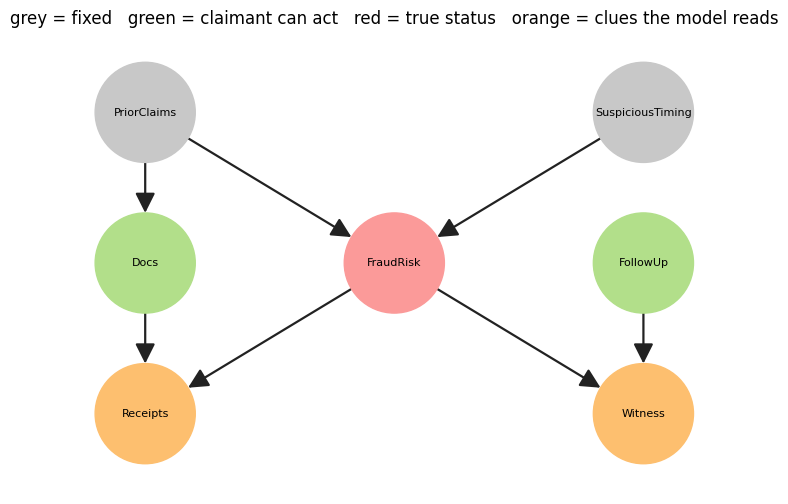

In [ ]:
scm_graph = nx.DiGraph([("PriorClaims", "FraudRisk"), ("SuspiciousTiming", "FraudRisk"),
                        ("PriorClaims", "Docs"), ("FollowUp", "Witness"),
                        ("FraudRisk", "Receipts"), ("Docs", "Receipts"), ("FraudRisk", "Witness")])
pos = {"PriorClaims": (0, 3), "SuspiciousTiming": (6, 3), "Docs": (0, 1.5), "FollowUp": (6, 1.5),
       "FraudRisk": (3, 1.5), "Receipts": (0, 0), "Witness": (6, 0)}
colors = {"PriorClaims": "#c8c8c8", "SuspiciousTiming": "#c8c8c8", "FraudRisk": "#fb9a99",
          "Docs": "#b2df8a", "FollowUp": "#b2df8a", "Receipts": "#fdbf6f", "Witness": "#fdbf6f"}
fig, ax = plt.subplots(figsize=(9, 6))
nx.draw(scm_graph, pos, ax=ax, with_labels=True, node_size=5200, font_size=8, arrowsize=30,
        edge_color="#222", width=1.6, node_color=[colors[n] for n in scm_graph.nodes])
ax.set_xlim(-1.2, 7.2); ax.set_ylim(-0.8, 3.8)
ax.set_title("grey = fixed   green = claimant can act   red = true status   orange = clues the model reads")
plt.show()

In [ ]:
features = ["PriorClaims", "SuspiciousTiming", "Receipts", "Witness"]
model = LogisticRegression(max_iter=2000).fit(history[features], history["FraudRisk"])

pred = model.predict_proba(history[features])[:, 1]
flagged = pred >= 0.5
is_fraud = history["FraudRisk"].values == 1

print("Weights the model learned (higher = pushes toward 'flag'):")
print(pd.Series(model.coef_[0], index=features).round(2).to_string())
print()
print(f"Share of all claims that are real fraud:     {is_fraud.mean():.1%}")
print(f"Share of all claims flagged:                 {flagged.mean():.1%}")
print(f"Share of real fraud the model catches:       {flagged[is_fraud].mean():.1%}")
print(f"Share of legitimate claims flagged by error: {flagged[~is_fraud].mean():.1%}")

Weights the model learned (higher = pushes toward 'flag'):
PriorClaims        5.800
SuspiciousTiming   3.330
Receipts           1.470
Witness            1.190

Share of all claims that are real fraud:     15.3%
Share of all claims flagged:                 14.7%
Share of real fraud the model catches:       88.2%
Share of legitimate claims flagged by error: 1.4%


Now we can give the model any new claim by entering its four values (prior claims, suspicious timing, receipts and witness). It returns a probability of high fraud risk, and the insurer flags the claim if that probability is 0.5 or higher. That is what we did for Maria.

**Share of all claims flagged: 14.7%**
Out of every 100 claims, the model flags about 15. This is close to the actual fraud rate (15.3%), so the model flags roughly as many claims as there is fraud.

**Share of real fraud the model catches: 88.2%**
Of every 100 fraudulent claims, the model flags about 88. That means it misses about 12 (FN).

**Share of legitimate claims flagged by error: 1.4%**
Of every 1,000 legitimate claims, about 14 are flagged by mistake. These are false alarms (FP), and Maria is one of them.

The numbers fit together. Roughly 15.3% of claims are fraud. Of those, 88.2% are caught, which is about 13.5% of all claims. Of the other 84.7% that are legitimate, 1.4% are flagged by mistake, which is about 1.2% of all claims. Add them and you get about 14.7%, the first number.

That also means roughly 92 out of every 100 flagged claims are truly fraudulent (13.5 out of 14.7; 0.153 × 0.882 ≈ 0.135, or 13.5% of all claims).

One caution is that these numbers were measured on the same history the model learned from. They are a good picture of how the model behaves, but on brand-new claims we would expect them to be slightly less good.

The model works well overall: it catches most real fraud and wrongly flags only a small share of legitimate claims. **Maria is one of that small share.**

In [ ]:
# values that are fed to the logistic regression model
maria = dict(PriorClaims=1, SuspiciousTiming=0, Docs=4.5, FollowUp=0, FraudRisk=0, Receipts=3.6, Witness=3.0)
maria_row = pd.DataFrame([maria])
p_maria = model.predict_proba(maria_row[features])[0, 1]

print(maria_row.T.rename(columns={0: "Maria"}).to_string())
print(f"\nModel's probability that Maria's claim is high fraud risk: {p_maria:.3f}")
print("Decision:", "FLAGGED for extra review" if p_maria >= 0.5 else "fast track")
print("Truth (known after review): legitimate claim")

                  Maria
PriorClaims       1.000
SuspiciousTiming  0.000
Docs              4.500
FollowUp          0.000
FraudRisk         0.000
Receipts          3.600
Witness           3.000

Model's probability that Maria's claim is high fraud risk: 0.964
Decision: FLAGGED for extra review
Truth (known after review): legitimate claim


Maria is a false positive

### Logistic Regression, Confusion Matrix, and Precision-Recall Tradeoff

**The trade-off is controlled by the threshold.** Our model flags a claim when its probability is 0.5 or higher.
- Lower the threshold (say to 0.3), and more claims are flagged. Fewer fraudulent claims slip through (fewer false negatives), but more honest claimants get flagged (more false positives).
- Raise the threshold (say to 0.7), and the reverse happens.

**What each mistake costs in our story**
- A false negative means a fraudulent claim goes down the fast track, and the insurer may pay out money it should not.
- A false positive means an honest claimant, like Maria, waits on a slower track. In our story a flag only triggers an extra review. It does not deny the claim.

**What that suggests here**
- Because a flag only adds a review, a false positive is a real cost to the claimant (delay) and to the insurer (reviewer time, and customer trust), but it is recoverable.
- Because a missed fraud means money paid out, many insurers accept more false positives to reduce false negatives.
- The balance changes with the details. If reviews are expensive or slow, or if flagged claimants are treated harshly, the case for fewer false positives gets stronger.

**The same logic elsewhere**
- A medical screening test usually tolerates false positives, because a missed disease is costly and a follow-up test is cheap.
- A system that automatically denies loans or blocks accounts usually has to guard against false positives, because the harm to the person is large and sudden.

We choose the threshold by putting a price on each type of mistake, and that price is a decision about people and money, not something the model can compute for you.

The model is **96% sure** that Maria's claim is high fraud risk, and it is wrong. Her receipts show some mismatches, her witness statements show some inconsistency, and she has filed claims before. Each of those, taken alone, is a modest nudge. Together they add up.

### Three kinds of answer to "why, and what can I do?"
This is the plan for the rest of the notebook. The same person, the same model, three levels of explanation:

| Rung | The explanation | The question it answers | What it needs |
|---|---|---|---|
| 1. Seeing | **Attribution** (SHAP, LIME) | Which inputs pushed the score up? | The model and data |
| 2. Doing | **Interventional analysis** | If claimants like Maria *changed* something, what would happen to the group? | A causal graph |
| 3. Imagining | **Counterfactuals and recourse** | For *Maria*, with everything unique to her, what would it take? | A graph plus equations |

### Rung 1: Which inputs pushed the score up? (SHAP)

SHAP is a popular way to explain a model's decision. For one claim, it splits the model's score into pieces and gives each input credit for how much it pushed the score up or down, compared with an average claim. Here we build it by hand to see exactly what it does.

**The idea:** start from the average claim, then give the model Maria's values one feature at a time and watch the score move. The order matters (a feature's effect depends on what is already known), so SHAP averages over *every possible order*. With four features there are only 16 groups of features to try, which is small enough to compute exactly.

- **Value of a group of features S:** the model's average score when the features in S are set to Maria's values and all the others are drawn from past claims.
- **A feature's credit:** its added effect when it joins a group, averaged over all groups, with the weights that make every ordering count equally.

Average claim's score (starting point): 0.156
  PriorClaims        adds +0.498
  SuspiciousTiming   adds -0.019
  Receipts           adds +0.164
  Witness            adds +0.165
Starting point + credits = 0.964   (the model's score for Maria: 0.964)


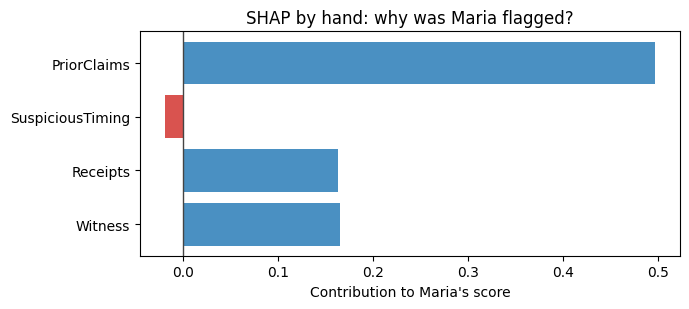

In [ ]:
background = history.sample(2000, random_state=0)[features].reset_index(drop=True)
x_maria = maria_row[features].iloc[0]

def value(S):
    X = background.copy()
    for f in S:
        X[f] = x_maria[f]                       # fix these features at Maria's values
    return model.predict_proba(X)[:, 1].mean()  # let the others vary like past claims

n = len(features)
shap_values = {}
for f in features:
    others = [g for g in features if g != f]
    total = 0
    for k in range(n):
        for S in combinations(others, k):
            weight = factorial(k) * factorial(n - k - 1) / factorial(n)
            total += weight * (value(S + (f,)) - value(S))
    shap_values[f] = total

base_value = value(())
print(f"Average claim's score (starting point): {base_value:.3f}")
for f, v in shap_values.items():
    print(f"  {f:18s} adds {v:+.3f}")
print(f"Starting point + credits = {base_value + sum(shap_values.values()):.3f}   (the model's score for Maria: {p_maria:.3f})")

fig, ax = plt.subplots(figsize=(7, 3.2))
names = list(shap_values)[::-1]
ax.barh(names, [shap_values[k] for k in names], color=["#4a90c2" if shap_values[k] >= 0 else "#d9534f" for k in names])
ax.axvline(0, color="#444", lw=1)
ax.set_xlabel("Contribution to Maria's score")
ax.set_title("SHAP by hand: why was Maria flagged?")
plt.tight_layout(); plt.show()

**Reading the result.** The credits add up exactly from the average claim (about 0.16) to Maria's score (0.96). The biggest single contributor is **PriorClaims**, then receipts and witness statements about equally. Suspicious timing contributes almost nothing.

That is a useful, honest picture of *what the model used*. Now notice what it does **not** say. Hold on to these three questions for later:
- Maria cannot change her prior claims. The biggest credit points at something she cannot act on.
- Is a receipt mismatch something Maria *caused* her own flag by? Or a symptom of something else?
- If Maria fixed her receipts, would her *claim* be any more legitimate, or only her *score* lower?

**What about LIME?** LIME does the same job with a different method: it nudges Maria's values a little, watches how the model's score moves, and fits a simple straight-line model around her. The answer looks different on the surface, but it lives on the same rung. Both describe **how the model behaves**. Neither tells us what would happen in the world if something were changed.

## Part 2: Opening the machine: the structural causal model

### A graph tells us who influences whom. Equations tell us how.
We have drawn graphs of the fraud story since the beginning. A graph shows **which** variables influence which. A **structural causal model (SCM)** adds two things:

1. **An equation for each variable**: how it is produced from its parents.
2. **A noise term for each variable**: everything unique to that case that we never measured.

Think of the graph as the skeleton and the equations as the muscles that make it move.

### You have already met an SCM, in disguise
Remember the probability table for FraudRisk: given prior claims and suspicious timing, how likely is a High rating?

| PriorClaims | SuspiciousTiming | P(FraudRisk = High) |
|---|---|---|
| Yes | Yes | 0.90 |
| Yes | No | 0.55 |
| No | Yes | 0.50 |
| No | No | 0.03 |

A table of probabilities is a **recipe with a dice roll**. Give each claim its own hidden random number *U* between 0 and 1, and write the equation:

> **FraudRisk = High if U < (the probability in the table), otherwise Low.**

**What is U, in Maria's claim?** Every claim carries hidden numbers of its own, one for each part of its story. They are never recorded in the data. We can only work them out afterward, by comparing what we observed with what the equations predict. We never see them directly, and they stay fixed for that claim. Maria's receipts show how this works. Given that she is legitimate and submitted 4.5 documents, the equation predicts a receipts mismatch of 4 + 3 × 0 − 0.5 × 4.5 = 1.75. Her actual receipts are 3.6. The gap, 3.6 − 1.75 = **+1.85**, is her U for receipts: her own bad luck with her paperwork. In the same way, her witness statements came out 2.0 worse than the equation predicts, so her U for witness is **+2.0**. No other claim has exactly these two numbers. They are what separate Maria from an average claim like hers, and they are why the model read her as suspicious. Later, when we ask what would have happened to Maria if she had submitted more documents, we keep these two numbers fixed. That keeps the answer about Maria and not about a typical claimant.

A claim with U = 0.40 whose parents are (Yes, No) has a 0.55 threshold, and 0.40 < 0.55, so it is High. The same U in the world where its parents were (No, No) would sit above 0.03, so it would be Low. **The same hidden number, run through different parents, gives a different answer.** Hold on to that idea. It is the key to rung 3.

**In short:** U is what is unique to one claim that the measured variables do not explain. For Maria's receipts, the equation predicts 1.75 and she has 3.6, so her U is the gap, +1.85. Nobody records it. We work it out by comparing what happened with what the equation expected. It belongs to Maria and stays fixed. That is how we can ask what would have happened to *her* if she had done something differently: we change what she did and keep her U.

Check that the recipe reproduces the base rate we saw in the fraud network:

In [ ]:
p_prior, p_timing = 0.15, 0.10
base_rate = sum((p_prior if a else 1 - p_prior) * (p_timing if b else 1 - p_timing) * FRAUD_P[(a, b)]
                for a in (0, 1) for b in (0, 1))
print(f"P(FraudRisk = High), by the recipe : {base_rate:.4f}")
print(f"Share High in our simulated claims : {history['FraudRisk'].mean():.4f}")

P(FraudRisk = High), by the recipe : 0.1532
Share High in our simulated claims : 0.1529


Same as before (0.1532, up to sampling noise in the simulated claims).

### The full machine for our claims
Every variable in this notebook is produced by an equation. Here they are in plain words:

| Variable | Equation | Noise (unique to each claim) |
|---|---|---|
| PriorClaims | Yes with probability 0.15* | a random number |
| SuspiciousTiming | Yes with probability 0.10 | a random number |
| FraudRisk | High if a random number falls below the table's probability | a random number |
| Docs | 4 + 3 × PriorClaims + noise | how thorough this claimant happened to be |
| FollowUp | Yes with probability 0.10 | a random number |
| **Receipts** | **4 + 3 × FraudRisk − 0.5 × Docs + noise** | **how unlucky this claim's paperwork was** |
| **Witness** | **1 + 3 × FraudRisk − 1.5 × FollowUp + noise** | **how muddled these particular statements were** |

* If below 0.15, PriorClaims is Yes. Otherwise it is No.

Read the two bold rows. Fraud makes receipts mismatch and witness statements inconsistent (a claimant padding a claim has to produce paperwork, and invented paperwork tends not to match). Thorough documents *reduce* mismatches, and a follow-up statement *reduces* inconsistency. Prior claimants tend to file more thoroughly, which will matter in a moment.

### The graph
Colors show who can do what: **grey** variables are fixed for the claimant, **green** are things the claimant can act on, **red** is the hidden true status, **orange** are the clues the model reads.

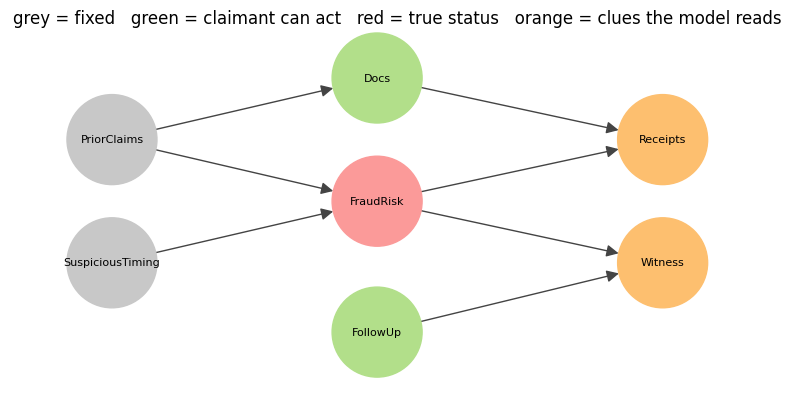

In [ ]:
scm_graph = nx.DiGraph([("PriorClaims", "FraudRisk"), ("SuspiciousTiming", "FraudRisk"),
                        ("PriorClaims", "Docs"), ("FraudRisk", "Receipts"), ("Docs", "Receipts"),
                        ("FraudRisk", "Witness"), ("FollowUp", "Witness")])
pos = {"PriorClaims": (0, 1.6), "SuspiciousTiming": (0, 0), "FraudRisk": (2.6, 0.8),
       "Docs": (2.6, 2.4), "FollowUp": (2.6, -0.9), "Receipts": (5.4, 1.6), "Witness": (5.4, 0)}
colors = {"PriorClaims": "#c8c8c8", "SuspiciousTiming": "#c8c8c8", "FraudRisk": "#fb9a99",
          "Docs": "#b2df8a", "FollowUp": "#b2df8a", "Receipts": "#fdbf6f", "Witness": "#fdbf6f"}
fig, ax = plt.subplots(figsize=(10, 4.6))
nx.draw(scm_graph, pos, ax=ax, with_labels=True, node_size=4200, font_size=8, arrowsize=18, edge_color="#444",
        node_color=[colors[n] for n in scm_graph.nodes])
ax.set_xlim(-1, 6.6); ax.set_ylim(-1.6, 3.0)
ax.set_title("grey = fixed   green = claimant can act   red = true status   orange = clues the model reads")
plt.show()

**Levers** are FollowUp and Docs

Two familiar shapes are hiding in this picture:
- **A fork.** FraudRisk points at both Receipts and Witness. They move together because of a common cause, exactly like shark bites and ice cream sales. Neither causes the other.
- **A confounding path.** Prior claims affect how many documents a claimant files, and also raise the chance of fraud, which pushes receipts up. So documents and receipts are linked through a **backdoor path** (Docs ← PriorClaims → FraudRisk → Receipts) in addition to the real causal arrow from Docs to Receipts.

### How a human reviewer would see Maria’s claim

Comparing a claim with typical claims is a normal part of a review, and our table of averages, aggregates of our historical data, is the kind of benchmark they could use.

It is only a starting point, though. Here is what such a comparison would show for Maria:
- Her receipts (3.6) are close to the average for fraudulent claims with a prior claim (3.48), and far from legitimate claims with a prior claim (0.51).
- Her witness value (3.0) is nearer the fraudulent average (3.85) than the legitimate one (0.83).

So the aggregates point toward fraud, the same way they led the model to flag her. An investigator who relied on them would reach the same wrong conclusion as the model.

What lets the investigator get it right is evidence specific to her claim, which the averages cannot give. Examples are checking whether each receipt mismatch has an innocent explanation, speaking with the witnesses, and confirming the loss itself. That is how a review can find a legitimate claim that looks like fraud on the numbers.

So the investigator's comparison with the history can raise questions, but only the investigation of her particular claim can settle them. The aggregates describe groups, and the verdict is about Maria. That is the same theme as the rest of the notebook.

In summary, an explanation is only useful if it describes the world and not just the model. Attribution tells you what the model used, and counterfactuals and recourse tell a person what they can actually do to affect a decision. Human judgment stays in the loop, but it works better when the tools around it are honest about what they can and cannot say.

### Seeing versus doing, again

How much does one extra document change the receipts mismatch? First we look at the data alone. Then we use the graph to account for the backdoor path.

In [ ]:
seeing = LinearRegression().fit(history[["Docs"]], history["Receipts"]).coef_[0]
adjusted = LinearRegression().fit(history[["Docs", "PriorClaims"]], history["Receipts"]).coef_[0]

rng_do = np.random.default_rng(21)
U = draw_noise(100000, rng_do)
base_world = world(U)
plus_one = world(U, do={"Docs": base_world["Docs"] + 1})            # force every claimant to submit one more document
doing = (plus_one["Receipts"] - base_world["Receipts"]).mean()

print(f"SEEING: slope of receipts on docs, just looking at the data  : {seeing:+.3f}")
print(f"Adjusting for PriorClaims (blocks the backdoor path)          : {adjusted:+.3f}")
print(f"DOING:  do(one more document) in the machine                  : {doing:+.3f}")

SEEING: slope of receipts on docs, just looking at the data  : -0.330
Adjusting for PriorClaims (blocks the backdoor path)          : -0.497
DOING:  do(one more document) in the machine                  : -0.500


The raw data alone, which is rung 1, gives 0.33. Rung 2 gives 0.5, and there are two ways to reach it:

- **Intervene in the machine.** We force one more document on every claim and see what changes. That gives 0.50.
- **Adjust for prior claims.** Using the graph, we hold prior claims fixed in the historical data. That gives 0.497, which is essentially the same.

The second way matters in practice. With real claims, we usually cannot force documents on claimants to see what happens. Adjusting lets us get the answer to the intervention question from data we already have, as long as the graph is right.

So the answer to "how much does one extra document change the receipts mismatch?" is 0.5. It comes from the graph plus the data, with the graph telling us what to hold fixed.



**Use the graph to account for the backdoor path.**

A backdoor path is a route in the graph that connects two variables **through a common cause, not through the cause-and-effect arrow between them.** It is called a backdoor because it starts by going backward, against an arrow pointing into the variable we are changing.



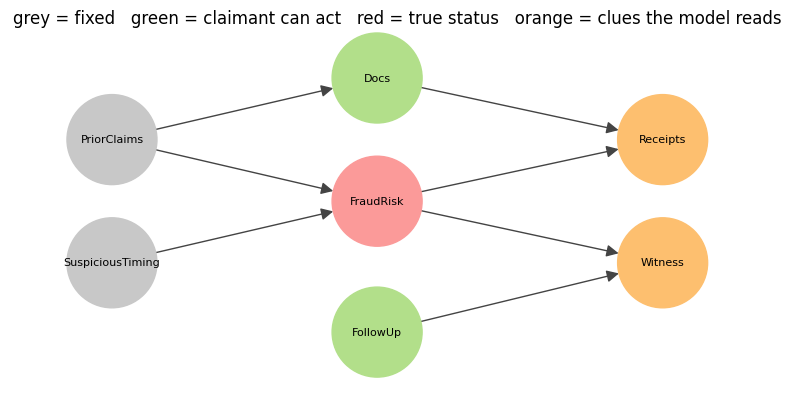

In [ ]:
scm_graph = nx.DiGraph([("PriorClaims", "FraudRisk"), ("SuspiciousTiming", "FraudRisk"),
                        ("PriorClaims", "Docs"), ("FraudRisk", "Receipts"), ("Docs", "Receipts"),
                        ("FraudRisk", "Witness"), ("FollowUp", "Witness")])
pos = {"PriorClaims": (0, 1.6), "SuspiciousTiming": (0, 0), "FraudRisk": (2.6, 0.8),
       "Docs": (2.6, 2.4), "FollowUp": (2.6, -0.9), "Receipts": (5.4, 1.6), "Witness": (5.4, 0)}
colors = {"PriorClaims": "#c8c8c8", "SuspiciousTiming": "#c8c8c8", "FraudRisk": "#fb9a99",
          "Docs": "#b2df8a", "FollowUp": "#b2df8a", "Receipts": "#fdbf6f", "Witness": "#fdbf6f"}
fig, ax = plt.subplots(figsize=(10, 4.6))
nx.draw(scm_graph, pos, ax=ax, with_labels=True, node_size=4200, font_size=8, arrowsize=18, edge_color="#444",
        node_color=[colors[n] for n in scm_graph.nodes])
ax.set_xlim(-1, 6.6); ax.set_ylim(-1.6, 3.0)
ax.set_title("grey = fixed   green = claimant can act   red = true status   orange = clues the model reads")
plt.show()

Here we want the effect of Docs on Receipts. There are two routes between them:

1. **The direct route (the one we want):** Docs → Receipts. This is the real effect of a document on the mismatch.
2. **The backdoor route (the one that misleads):** Docs ← PriorClaims → FraudRisk → Receipts. Read it from the left: prior claims push Docs up, and prior claims also raise the chance of fraud, which raises receipts mismatch.

The backdoor route passes along association, but none of it is the effect of a document. When we look at the raw data, the two routes are mixed together. Claims with many documents also tend to be claims with a push upward on receipts, because both come from prior claims. That is why the raw slope (−0.33) understates the real effect (−0.5).

This is the same shape as the fork we saw earlier, where a common cause makes two things move together even though neither causes the other.

**Blocking it:** We close the backdoor by holding the common cause fixed, which is conditioning again. Comparing claims with the same prior-claims status blocks the route through PriorClaims. What remains is the direct route, and the slope matches the truth (−0.497).

The rule of thumb is to find the routes that start with an arrow into the variable you are changing, and block them. Never block the direct route, which would remove the effect you want to measure.

The condition is the value PriorClaims is held at. It has two possible values, so there are two conditions:

- **PriorClaims = 0** (no prior claim)
- **PriorClaims = 1** (has a prior claim)

We do the comparison under both conditions and then combine the results:
- Among claims with PriorClaims = 0, how do receipts change with documents?
- Among claims with PriorClaims = 1, how do receipts change with documents?

- Within the group with PriorClaims = 0, compare claims with fewer documents to claims with more documents. How do their receipts differ?
- Within the group with PriorClaims = 1, do the same comparison.



This is how the graph helps us get a better answer to a specific question about Docs: **what does one extra document actually do to the receipts mismatch?**

Without the graph, all we have is the raw data. It gives a slope (−0.33) that mixes the real effect of documents with the influence of prior claims. With the graph, we can see that mixing and remove it, and we get −0.5, the real effect.

So the graph does not tell us anything new about the documents themselves. It tells us how to read the data properly, so the number we take away is the effect of the document and nothing else.

That matters for Maria. Documents are her main lever, and her advice depends on how much each one helps. A better understanding of Docs means advice she can rely on.

DoWhy can do the identification and estimation for us:

In [ ]:
from dowhy import CausalModel

gml = '''graph [directed 1
 node [id "PriorClaims" label "PriorClaims"] node [id "SuspiciousTiming" label "SuspiciousTiming"]
 node [id "FraudRisk" label "FraudRisk"] node [id "Docs" label "Docs"] node [id "FollowUp" label "FollowUp"]
 node [id "Receipts" label "Receipts"] node [id "Witness" label "Witness"]
 edge [source "PriorClaims" target "FraudRisk"] edge [source "SuspiciousTiming" target "FraudRisk"]
 edge [source "PriorClaims" target "Docs"] edge [source "FraudRisk" target "Receipts"]
 edge [source "Docs" target "Receipts"] edge [source "FraudRisk" target "Witness"]
 edge [source "FollowUp" target "Witness"]]'''

dw_model = CausalModel(data=history.iloc[:20000], treatment="Docs", outcome="Receipts", graph=gml)
dw_estimand = dw_model.identify_effect(proceed_when_unidentifiable=True)
dw_estimate = dw_model.estimate_effect(dw_estimand, method_name="backdoor.linear_regression")
print("Variables DoWhy says to adjust for:", dw_estimand.get_backdoor_variables())
print(f"DoWhy's estimate of one more document on receipts: {dw_estimate.value:+.3f}   (truth -0.500)")

Variables DoWhy says to adjust for: ['FraudRisk']
DoWhy's estimate of one more document on receipts: -0.495   (truth -0.500)


DoWhy read our graph and found the backdoor path (Docs ← PriorClaims → FraudRisk → Receipts).

**Why this machine matters.** An SCM is a machine we can *run*. We can run it as it is, we can run it with a variable forced to a new value (`do`), and, as we will see in Part 5, we can run it again for one specific person while keeping *their* noise fixed. All three rungs live in this one machine.

Our machine from Part 1 did two things:

| | What it is | In the code |
|---|---|---|
| **The machine** | The rules for how each variable is made | `FRAUD_P`, `eq_receipts`, `eq_witness`, and the `world` function |
| **The data** | What the machine produces when we run it | `history`, the table of 40,000 claims |

In `world`, each line is one equation:
- `d["Receipts"] = 4.0 + 3.0 * d["FraudRisk"] + docs_effect * d["Docs"] + U["receipts"]` is the equation for receipts.
- `d["Docs"] = 4 + 3.0 * d["PriorClaims"] + U["docs"]` is the equation for documents.
- `d["FraudRisk"] = (U["fraud"] < p)` is the fraud rule that uses the table of probabilities.

The last line, `history = world(draw_noise(...))`, runs the machine once to create the table.

What makes it a machine and not only a data generator is that we run the same code again later with changes. For example, the notebook calls `world(U, do={"Docs": ...})` to force every claimant's documents to a new value and see what happens. That is the do operation, and it is only possible because the rules are written down and can be re-run.

In the first part of the notebook, this cell is only a way to get data. From Part 2 on, it is the machine we work with.

## Part 3: Where rung 1 stops

Note: The irony of 5810
* We had a model like this logistic regression model that misclassifies
* And noone could say why
* Hence XAI (SHAP and Lime)

SHAP (explainability) described the model's behavior. Now that we have a machine for the world, we can test what that description is worth for deciding what to *do*. Three tests.

### Test 1: Fix the clue, or fix the cause?
SHAP (explanability) gave **Receipts** a large credit for Maria's flag. A natural reading is: *"receipts mismatch raised her score, so cleaning up receipts must be the way to avoid a flag."* Let's test that reading in the machine. Force every claimant's receipts to look clean, and ask two questions: what happens to the model's flags, and what happens to the real fraud?

In [ ]:
rng_g = np.random.default_rng(9)
Ug = draw_noise(100000, rng_g)
before = world(Ug)
after_clean = world(Ug, do={"Receipts": np.full(100000, 0.5)})     # do(Receipts = clean) for everyone

def report(label, df):
    flags = model.predict_proba(df[features])[:, 1] >= 0.5
    fraud = df["FraudRisk"].values == 1
    print(f"{label:34s} real fraud rate {fraud.mean():.4f}   fraud the model catches {flags[fraud].mean():.1%}")

report("As things are", before)
report("After do(Receipts = clean)", after_clean)

As things are                      real fraud rate 0.1534   fraud the model catches 88.1%
After do(Receipts = clean)         real fraud rate 0.1534   fraud the model catches 32.0%


The **real fraud rate does not move**: 0.1534 before and 0.1534 after. Fraud causes the receipt problem, and not the other way around, so fixing the receipts leaves the fraud where it was. The only thing that changed is the model: it now catches **32%** of real fraud instead of 88%. We would have spent effort, hidden a warning sign, and blinded the model, all at once. It is the same lesson as before: **fixing a clue does not fix its cause, and it can destroy the clue.**

SHAP's credit for receipts was accurate about the *model*. It was silent about the *world*.

### Test 2: Is the credit something a person can use?
The largest credit went to **PriorClaims**. Maria cannot change her history. An attribution method has no idea which inputs a person can act on, because that is not a fact about data. It is a fact about the world and about the person.

### Test 3: Group or person?
SHAP averages over past claims to build its starting point, so every credit is measured against the *average* claim. Maria's question is about *Maria*. The average claim contains none of Maria's own noise: how unlucky *her* receipts happened to be, how muddled *her* witness statements were. Averages cannot see that, and she is the one who was flagged.

**So rung 1 explanations describe the model well, and they are not the same as advice.** To give advice we need to climb.

* **Is Generative AI stuck in rung 1 or can it climb the ladder?**
* **What about AGI?**

## Part 4: Rung 2: What if claimants like Maria changed something?

Rung 2 is about **groups under intervention**. Which actions can claimants like Maria actually take? Looking at the graph, two things are green: **Docs** and **FollowUp**. Prior claims and timing are fixed.

**The question for the group:** take claimants who look like Maria (legitimate, prior claims, no suspicious timing, 4.5 on the docs scale, no follow-up). What share of them does the model flag today? And if all of them submitted more documents (`do(Docs = ...)`), what share would be flagged?

Notice we are not conditioning on being flagged. We are describing a **group**, forcing a change, and letting each person's noise come out however it comes out.

                Share flagged
Extra documents              
0                       23.4%
1                       15.5%
2                        9.6%
3                        5.5%
4                        2.9%
5                        1.4%
6                        0.7%


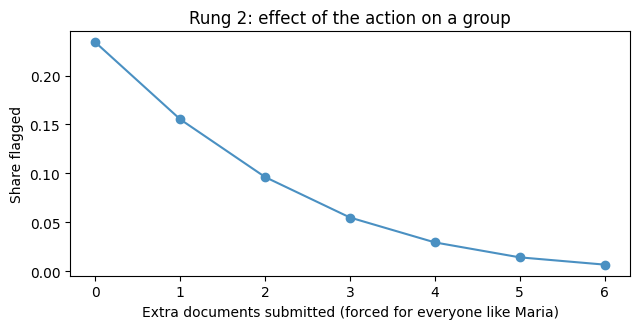

In [ ]:
N = 100000
U_like = draw_noise(N, np.random.default_rng(5))
fixed = dict(PriorClaims=np.ones(N, int), SuspiciousTiming=np.zeros(N, int),
             FraudRisk=np.zeros(N, int), FollowUp=np.zeros(N, int))

rows = []
for extra in [0, 1, 2, 3, 4, 5, 6]:
    like = world(U_like, do={**fixed, "Docs": np.full(N, 4.5 + extra)})
    share = (model.predict_proba(like[features])[:, 1] >= 0.5).mean()
    rows.append((extra, share))
rung2 = pd.DataFrame(rows, columns=["Extra documents", "Share flagged"]).set_index("Extra documents")
print(rung2.assign(**{"Share flagged": rung2["Share flagged"].map("{:.1%}".format)}).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(rung2.index, rung2["Share flagged"], marker="o", color="#4a90c2")
ax.set_xlabel("Extra documents submitted (forced for everyone like Maria)")
ax.set_ylabel("Share flagged")
ax.set_title("Rung 2: effect of the action on a group")
plt.tight_layout(); plt.show()

**Reading the result.** About **23%** of legitimate claimants like Maria are flagged today. If they all submitted four more documents, that would drop to about **3%**, and with six more to under 1%. For a *group*, extra documentation works, and it works through the arrow Docs → Receipts → model score.

This is a rung 2 answer: data plus a graph, no experiment. It describes the **average** effect on people like Maria. It cannot say whether the action will work for Maria in particular.

**A warning that connects to the earlier lesson.** The model reads *Receipts*, and documents feed *Receipts*. So documents lower the score through the receipts, not through the fraud. For a legitimate claimant that is fair: better paperwork really does remove innocent mismatches. We will return to what happens when *everyone* does it.

Documents affect the model’s score through one route: Docs → Receipts → the model’s score. They do not go through FraudRisk, because Docs has no arrow into fraud. So extra documents lower the model's score by improving the receipts, while leaving the real fraud status unchanged.

Confounding was the backdoor path: PriorClaims is a common cause of both Docs and FraudRisk, so it mixed itself into the raw slope between documents and receipts. That is a problem with measuring the effect of documents.

## Part 5: Rung 3: What would it take for *Maria*?

So far we have looked, through a model, at a cabinet of individual closed drawers (claims) as a whole, estimating the average of what is inside its drawers. Now we turn to one individual drawer.

### The individual's drawer
Every claim has an outcome in each possible world. We only see the world that happened.

Rung 2 never opens the drawer. It estimates the **average** of what is inside, by borrowing from similar people. Rung 3 asks for something sharper: *what is in the drawer for this one person?* To answer, we need a machine whose equations can **generate** the drawer's contents, and that is exactly what the SCM is. The machine is only as good as its equations, which is why rung 3 costs more assumptions than rung 2.

### Three moves
The same hidden random number, run through different parents, gives a different answer. Maria's hidden numbers are her noise. You may know noise as the residual, the difference between the actual value and the predicted value. Noise is never recorded in the data, but we can **recover it from what we observed**. Then we hold it fixed while we change one thing. Recovering it is like updating what we believe about Maria after seeing her claim.

1. **Recall (abduction).** Use Maria's observed values to work out her own noise.
2. **Change (action).** Set the one thing we want to change.
3. **Replay (prediction).** Run the equations forward with Maria's *same* noise.

**Move 1: recall.** We know Maria's receipts and witness values, her documents, her follow-up, and (after review) her true status. Every equation can be solved for its noise:

In [ ]:
u_receipts = maria["Receipts"] - eq_receipts(maria["FraudRisk"], maria["Docs"], 0.0)
u_witness  = maria["Witness"]  - eq_witness(maria["FraudRisk"], maria["FollowUp"], 0.0)

print(f"Maria's receipt noise : {u_receipts:+.2f}   (typical claims vary by about 1.2, so this is {u_receipts/1.2:.1f} standard deviations unlucky)")
print(f"Maria's witness noise : {u_witness:+.2f}   (typical claims vary by about 1.5, so this is {u_witness/1.5:.1f} standard deviations unlucky)")

Maria's receipt noise : +1.85   (typical claims vary by about 1.2, so this is 1.5 standard deviations unlucky)
Maria's witness noise : +2.00   (typical claims vary by about 1.5, so this is 1.3 standard deviations unlucky)


Maria is a legitimate claimant whose paperwork and witness statements both happened to come out **worse than the equations predict**. That is *her* noise. It is what the average claim does not have, and it is exactly why a model that reads these clues flagged her.

**Moves 2 and 3: change and replay.** Now change her documents and replay her own equations with her own noise:

In [ ]:
def counterfactual_maria(extra_docs=0, follow_up=None):
    docs = maria["Docs"] + extra_docs
    follow = maria["FollowUp"] if follow_up is None else follow_up
    r = eq_receipts(maria["FraudRisk"], docs, u_receipts)     # her own noise, new documents
    w = eq_witness(maria["FraudRisk"], follow, u_witness)     # her own noise, new follow-up
    x = pd.DataFrame([dict(PriorClaims=maria["PriorClaims"], SuspiciousTiming=maria["SuspiciousTiming"],
                           Receipts=r, Witness=w)])
    return r, w, model.predict_proba(x[features])[0, 1]

rows = []
for extra in range(0, 8):
    r, w, p = counterfactual_maria(extra)
    rows.append((extra, r, w, p, "cleared" if p < 0.5 else "still flagged"))
cf_table = pd.DataFrame(rows, columns=["Extra documents", "Her receipts", "Her witness", "Model's probability", "Decision"])
print(cf_table.round(3).to_string(index=False))

 Extra documents  Her receipts  Her witness  Model's probability      Decision
               0         3.600        3.000                0.964 still flagged
               1         3.100        3.000                0.927 still flagged
               2         2.600        3.000                0.860 still flagged
               3         2.100        3.000                0.746 still flagged
               4         1.600        3.000                0.586 still flagged
               5         1.100        3.000                0.405       cleared
               6         0.600        3.000                0.246       cleared
               7         0.100        3.000                0.136       cleared


**Here is the difference between rung 2 and rung 3.**
- **Rung 2 said:** four extra documents would lower the flagged share among claimants like Maria from 23% to about 3%. That works for nearly everyone.
- **Rung 3 says:** for *Maria*, four extra documents is **not enough**. Her probability only falls to about 0.59, and she is still flagged. She needs **five**.

Why? Because she is one of the unlucky ones. Her noise was large, so she needs a bigger change than a typical claimant. The group answer was not wrong. It just was not an answer *about her*.

Notice the phrase "typical claimants" hides a lot of people. Some of them clear with one or two documents, some need more. **A group average cannot tell Maria which one she is. A counterfactual can.**

### The imagined world, side by side
Two worlds share the same hidden noise. Only the documents differ:

| | Actual world (Maria today) | Imagined world (five more documents) |
|---|---|---|
| Documents | 4.5 | 9.5 |
| Receipts noise | +1.85 | +1.85 (same) |
| Receipts | 3.6 | 1.1 |
| Witness noise | +2.00 | +2.00 (same) |
| Witness | 3.0 | 3.0 (follow-up unchanged) |
| Model's probability | 0.96, flagged | 0.41, cleared |

This pairing of worlds with shared noise is the **twin network**. The individual drawer for Maria holds the right-hand column.

## Part 6: Counterfactual explanations: the nearest change

A **counterfactual explanation** answers a different question: *what is the smallest change to the model's inputs that would flip the decision?* ("You would have been approved if your income were a little higher.") It is a popular way to explain decisions because it is concrete, and it does not need to open the model.

For a logistic model the nearest point on the decision boundary can be computed directly. We measure distance in standardized units, so a change in one feature is comparable to a change in another.

In [ ]:
mu, sd = history[features].mean(), history[features].std()
w_std = model.coef_[0] * sd.values                         # weights in standardized units
b_std = model.intercept_[0] + (model.coef_[0] * mu.values).sum()
z = (x_maria.values - mu.values) / sd.values               # Maria in standardized units
score = w_std @ z + b_std                                  # her score on the log-odds scale

margin = 0.05                                              # land just across the boundary
z_new = z - ((score + margin) / (w_std @ w_std)) * w_std   # shortest move across
x_new = z_new * sd.values + mu.values

nearest = pd.DataFrame({"Maria today": x_maria.values, "Nearest cleared point": x_new}, index=features)
nearest["Change"] = nearest["Nearest cleared point"] - nearest["Maria today"]
print(nearest.round(2).to_string())

                  Maria today  Nearest cleared point  Change
PriorClaims             1.000                  0.850  -0.150
SuspiciousTiming        0.000                 -0.060  -0.060
Receipts                3.600                  2.750  -0.850
Witness                 3.000                  2.130  -0.870


Read the suggestion as Maria would:
- **PriorClaims: 1 → 0.85.** She is being told to have filed 0.15 fewer prior claims. That is not a number of claims, and it is not something she can change.
- **SuspiciousTiming: 0 → −0.06.** A negative amount of suspicion.
- **Receipts: 3.6 → 2.8** and **Witness: 3.0 → 2.1.** She is told to change her receipts and her witness statements directly, as if they were dials.

The nearest change is mathematically valid and practically useless. It has three flaws, and each one points at something rung 3 needs:

1. **It ignores what can be changed.** Prior claims are fixed. Fractions of a claim do not exist.
2. **It treats features as independent knobs.** Maria cannot edit her receipts. She can only submit documents, and *then* the receipts change, through the arrow in the graph. The suggestion skips the causal chain.
3. **It ignores who she is.** It is the nearest point in feature space, which has nothing to say about how her own noise would respond to anything she does.

To fix this we need the machine again.

## Part 7: Actionable algorithmic recourse

**Recourse** asks for the advice Maria actually needs: *which actions can she take, at what cost, so that the outcome changes?* It adds three ingredients to the counterfactual:

1. **Actionable features only.** Her levers are documents and a follow-up statement. Prior claims and timing are off the table.
2. **A cost for each action.** Say each extra document costs 1 unit of effort, and arranging a follow-up statement costs 4.
3. **The causal consequences of the action.** Acting on documents changes receipts *through the graph*, with Maria's own noise held fixed. We use the replay machine from Part 5.

Recall:
* The price (1 per document) tells us what the action costs Maria.
* The effect (0.5 per document) tells us how much one document lowers her receipts mismatch.

The recourse search uses both. It tries combinations of actions, uses the effect to work out whether each combination clears her, and uses the costs to pick the cheapest one that does.

**The search:** try every combination of actions, replay Maria's equations for each, and keep the ones that clear her. Then pick the cheapest.

In [ ]:
COST_DOC, COST_FOLLOWUP = 1, 4

rows = []
for extra in range(0, 9):
    for fu in (0, 1):
        r, w, p = counterfactual_maria(extra, follow_up=fu)
        rows.append(dict(ExtraDocs=extra, FollowUp=fu, Cost=extra * COST_DOC + fu * COST_FOLLOWUP,
                         Probability=p, Cleared=p < 0.5))
plans = pd.DataFrame(rows)

print("Cheapest plans that clear Maria:")
print(plans[plans["Cleared"]].sort_values(["Cost", "ExtraDocs"]).head(5).round(3).to_string(index=False))
print()
print("Follow-up statement alone (no extra documents):")
print(plans[(plans["ExtraDocs"] == 0) & (plans["FollowUp"] == 1)].round(3).to_string(index=False))

Cheapest plans that clear Maria:
 ExtraDocs  FollowUp  Cost  Probability  Cleared
         5         0     5        0.405     True
         6         0     6        0.246     True
         3         1     7        0.330     True
         7         0     7        0.136     True
         4         1     8        0.191     True

Follow-up statement alone (no extra documents):
 ExtraDocs  FollowUp  Cost  Probability  Cleared
         0         1     4        0.816    False


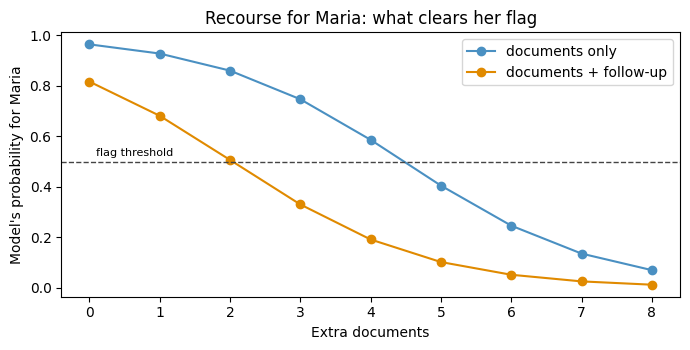

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for fu, label, color in [(0, "documents only", "#4a90c2"), (1, "documents + follow-up", "#e08a00")]:
    sub = plans[plans["FollowUp"] == fu]
    ax.plot(sub["ExtraDocs"], sub["Probability"], marker="o", label=label, color=color)
ax.axhline(0.5, color="#444", ls="--", lw=1)
ax.text(0.1, 0.52, "flag threshold", fontsize=8)
ax.set_xlabel("Extra documents"); ax.set_ylabel("Model's probability for Maria")
ax.set_title("Recourse for Maria: what clears her flag")
ax.legend(); plt.tight_layout(); plt.show()

### Maria's Recourse

**How to read the chart**
- The horizontal axis is the number of extra documents Maria submits.
- The vertical axis is the model's probability that her claim is high fraud risk.
- The dashed line is the flag threshold at 0.5. When a line is **above** it, she is flagged. When a line drops **below** it, she is cleared.

**The blue line (documents only)**
- With no extra documents she starts at 0.96, which is her actual flag.
- Each extra document lowers her receipts mismatch, which lowers the model's score.
- At four documents she is at about 0.59, still flagged.
- At five documents she falls to about 0.41, below the line.

**The orange line (documents plus a follow-up statement)**
- The follow-up lowers her witness inconsistency, so the whole line starts lower. With zero documents it begins at about 0.82.
- It drops below the threshold sooner, at about three documents (probability about 0.33).
- A follow-up alone, with no extra documents, is not enough, since 0.82 is still above the line.

**Why the notebook picks five documents.** Each document costs 1 and a follow-up costs 4.
- Five documents alone cost 5.
- Three documents plus a follow-up cost 3 + 4 = 7.

So the orange plan needs fewer documents, but it costs more overall. The cheapest plan that clears Maria is five extra documents.

**The big picture.** Both lines come from the same idea. Maria changes something she can act on (documents or a follow-up), which changes the clues the model reads (receipts and witness), which lowers her score. Her own hidden numbers stay fixed throughout, which is why the answer is about Maria and not a typical claimant.

Compare this with every earlier answer:

| Explanation | What it told Maria |
|---|---|
| SHAP (rung 1) | Prior claims were the biggest reason (which she cannot change) |
| Counterfactual explanation | Change your prior claims by 0.15 and your receipts and witness statements directly |
| Group analysis (rung 2) | Four more documents works for nearly everyone like you |
| **Recourse (rungs 2 and 3)** | **For you, five more documents, at a cost of 5** |

Each answer is correct about what it measures. Only the last one is something Maria can act on.

## Part 8: Honest limits

Everything above rests on a machine we built, so the machine deserves some suspicion. Three limits worth knowing.

### Limit 1: The advice is only as good as the equations
We told Maria that five documents would clear her because **each document lowers receipts by 0.5**. That number came from our assumed machine. Suppose the real world is different, and a document only lowers receipts by 0.1. The advice would sound identical, and it would fail:

In [ ]:
for effect in (-0.5, -0.1):
    r = maria["Receipts"] + effect * 5                         # five extra documents, under each world's rule
    x = pd.DataFrame([dict(PriorClaims=1, SuspiciousTiming=0, Receipts=r, Witness=maria["Witness"])])
    p = model.predict_proba(x[features])[0, 1]
    print(f"If one document changes receipts by {effect:+.1f}: after five documents her probability is {p:.3f}   "
          f"({'cleared' if p < 0.5 else 'still flagged'})")

If one document changes receipts by -0.5: after five documents her probability is 0.405   (cleared)
If one document changes receipts by -0.1: after five documents her probability is 0.927   (still flagged)


Same advice, different world, opposite outcome. This is the same warning we gave about every graph: **the graph is an assumption.** Estimating the effect of a document from data (as we did with adjustment earlier) is how we check it, and refuters stress-test it, but no test proves the equations are right. Recourse is advice conditional on a causal story, and it should be presented that way.

### Limit 2: When everyone follows the advice
Recourse is advice for *one person*. What happens when it becomes advice for *everyone*? Suppose the insurer publishes the recipe, and every claimant, honest or not, submits four more documents:

In [ ]:
everyone = world(Ug, do={"Docs": before["Docs"] + 4})
report("As things are", before)
report("After everyone submits 4 more docs", everyone)

As things are                      real fraud rate 0.1534   fraud the model catches 88.1%
After everyone submits 4 more docs real fraud rate 0.1534   fraud the model catches 61.3%


The **real fraud rate is unchanged** (0.1534), but the model now catches only **61%** of it, down from 88%. A claimant who is padding a claim can also submit documents, and thorough-looking paperwork lowers the receipts clue for them too. The advice that helps Maria **weakens the very clue the model relied on**. It is the receipts lesson again, at the scale of a whole population.

This is a real tension in recourse: **the more useful and public the advice, the less informative the signal becomes.** Responsible systems think about this up front, for example by basing decisions on things that are hard to fake, or by using the advice to route claims to a person and not to automatically clear them.

### Limit 3: Whose job is it to change?
Recourse puts the burden of change on the person subject to the decision. That is only fair if:
- the action is **really within their reach** (five extra documents may be easy for some claimants and costly for others),
- the **costs are comparable** across people (our cost of 1 per document is an assumption),
- and the decision itself is **reasonable to begin with**. Maria was flagged because of noise in her paperwork. A better remedy might be fixing the model, not giving Maria homework.

Explanations should be honest about which of these they assume.

## Wrap-up

**The ladder, applied to one decision**

| Rung | Tool | What it told us about Maria | Limit |
|---|---|---|---|
| 1. Seeing | SHAP, LIME | Which inputs the model used: prior claims, receipts, witness | Describes the model, not the world; says nothing about what can be changed |
| 2. Doing | Interventions on the SCM | Extra documents clear nearly everyone like her | Group average, not about her |
| 3. Imagining | Counterfactual replay with her own noise | For her, four documents is not enough and five is | Needs equations, so needs more assumptions |
| 3, made practical | Actionable recourse | Five more documents is the cheapest plan | Only as good as the equations, and can weaken the signal if everyone follows it |

**The takeaways**
1. **Attribution is not advice.** SHAP and LIME explain what a model *used*. They sit on the first rung.
2. An **SCM** is a graph plus an equation and a noise term for each variable. A CPT is a recipe with a dice roll, and the same dice roll can be replayed in a different world.
    - **Unknown:** U is never recorded in the data. We can only work it out by comparing what happened with what the equations predict.
    - **Unique for each individual:** every claim has its own U, and it stays fixed for that claim.
3. **Rung 2** answers "what if people like her did X?" for a group. **Rung 3** answers it for the one person, by recalling her noise, changing one thing, and replaying.
4. The **individual's drawer** holds a case's outcomes in worlds that did not happen. An SCM is the machine that can generate them.
5. A **counterfactual explanation** (the nearest change) is easy to compute and often useless: it can change fixed features and treat effects as independent dials.
6. **Recourse** adds actionability, costs, and causal consequences. It is advice conditional on a causal story, and that story is an assumption.
7. Advice that everyone follows can weaken the signal it was based on. Fixing a clue does not fix its cause.

## Reflection (activity)
Start a new text cell and write about **100–150 words** responding to this prompt:

*Think of an automated decision that affects people (a loan, a job screen, an insurance flag, a content moderation action). Describe what a SHAP-style explanation would say, then what recourse the affected person would actually need. Name one thing they cannot change, one thing they can, and one way the advice could backfire if everyone followed it.*